# 06 · Analysis E: error analysis
Where do the models make large errors, and do they fail in the same places?
Set `SPLIT = "val"` to analyse the validation year now. Switch to `"test"` only **after** notebook 05 has scored and
frozen 2019, and do not change any model, feature or setting because of what you see there (the test year is scored once).
Everything here only **reads** saved predictions, so nothing is refitted.

In [10]:
import sys, os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M, models as mo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(ev.FIGS / f"{name}.png", dpi=150); plt.show()

SPLIT = "test"                      # "val" now; "test" only after Gate G2
MODELS = [n for n in mo.MODELS if all(ev.pred_path(SPLIT, n, h).exists() for h in ev.HORIZONS)]
print("SPLIT:", SPLIT, "| models with saved predictions at both horizons:", MODELS)

SPLIT: test | models with saved predictions at both horizons: ['ridge', 'pca_ridge', 'dt', 'rf', 'ada', 'gb', 'xgb', 'lgbm', 'cat']


## 0. Load: one table per horizon, one prediction column per model
Columns added: `err` = prediction minus actual (vehicles per 15 min), `abs_err`, and segment labels.
Peak = weekday 06:00-09:59 or 15:00-18:59 (by target time). "Sudden change" = how far the target moved away from the
latest reading, in units of the sensor's usual flow (quartiles).

In [11]:
KEEP = ["split", "time", "target_time", "ID2", "corridor", "role", "sc", "y", "y_raw", "flow_t", "precip_mm", "is_holiday", "is_weekend"]
D = {}
for h in ev.HORIZONS:
    tab = ev.load_table(h, columns=KEEP)
    rows0 = None
    for n in MODELS:
        p = pd.read_parquet(ev.pred_path(SPLIT, n, h))
        if rows0 is None:
            rows0 = p["row"].to_numpy(); d = tab.loc[rows0].copy()
        assert np.array_equal(rows0, p["row"].to_numpy()), f"{n} h={h}: different rows than the first model"
        d[f"pred_{n}"] = p["pred"].to_numpy("float64")
    t = d["target_time"]
    hr = t.dt.hour
    d["hour"] = hr
    d["weekend"] = np.where(d["is_holiday"] > 0, "holiday", np.where(d["is_weekend"] > 0, "weekend", "weekday"))
    d["peak"] = np.where((d["weekend"] == "weekday") & (hr.between(6, 9) | hr.between(15, 18)), "peak", "off-peak")
    d["rain"] = np.where(d["precip_mm"] > 0.1, "rain", "dry")
    d["change"] = pd.qcut((d["y"] - d["flow_t"]).abs().rank(method="first"), 4, labels=["Q1 steady", "Q2", "Q3", "Q4 sudden"])
    d["level"] = pd.qcut(d["y"].rank(method="first"), 3, labels=["low flow", "mid flow", "high flow"])
    for n in MODELS:
        d[f"err_{n}"] = d[f"pred_{n}"] - d["y_raw"]
    D[h] = d
    print(f"{h}-minute horizon: {len(d):,} rows, {d['ID2'].nunique()} sensors")

15-minute horizon: 868,158 rows, 100 sensors
60-minute horizon: 868,102 rows, 100 sensors


## 1. Error by segment (WAPE %, lower is better)
WAPE = total absolute error / total actual flow in the segment, so busy and quiet segments are comparable.

In [12]:
def wape_seg(d, col):
    rows = {}
    for key, g in d.groupby(col, observed=True):
        rows[key] = {mo.LABEL[n]: M.wape(g["y_raw"], g[f"pred_{n}"]) * 100 for n in MODELS}
    return pd.DataFrame(rows).T
SEGS = ["peak", "weekend", "rain", "change", "level", "role"]
tables = {}
for h in ev.HORIZONS:
    for s in SEGS:
        t = wape_seg(D[h], s); t.index.name = s
        tables[(h, s)] = t
        t.round(2).to_csv(ev.RESULTS / f"error_{SPLIT}_h{h}_{s}.csv")
    print(f"--- {h}-minute horizon ---")
    for s in SEGS:
        print(tables[(h, s)].round(2).to_string(), "\n")

--- 15-minute horizon ---
          Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
peak                                                                                                                
off-peak   6.33         6.33           5.88           5.54      5.73               5.70     5.44      5.43      5.48
peak       5.63         5.63           5.39           5.13      5.25               5.19     5.05      5.04      5.05 

         Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
weekend                                                                                                            
holiday   8.13         8.13           6.69           6.26      6.51               6.47     6.09      6.04      6.11
weekday   6.14         6.14           5.74           5.43      5.58               5.57     5.36      5.35      5.39
weekend   5.79         5.79           5.

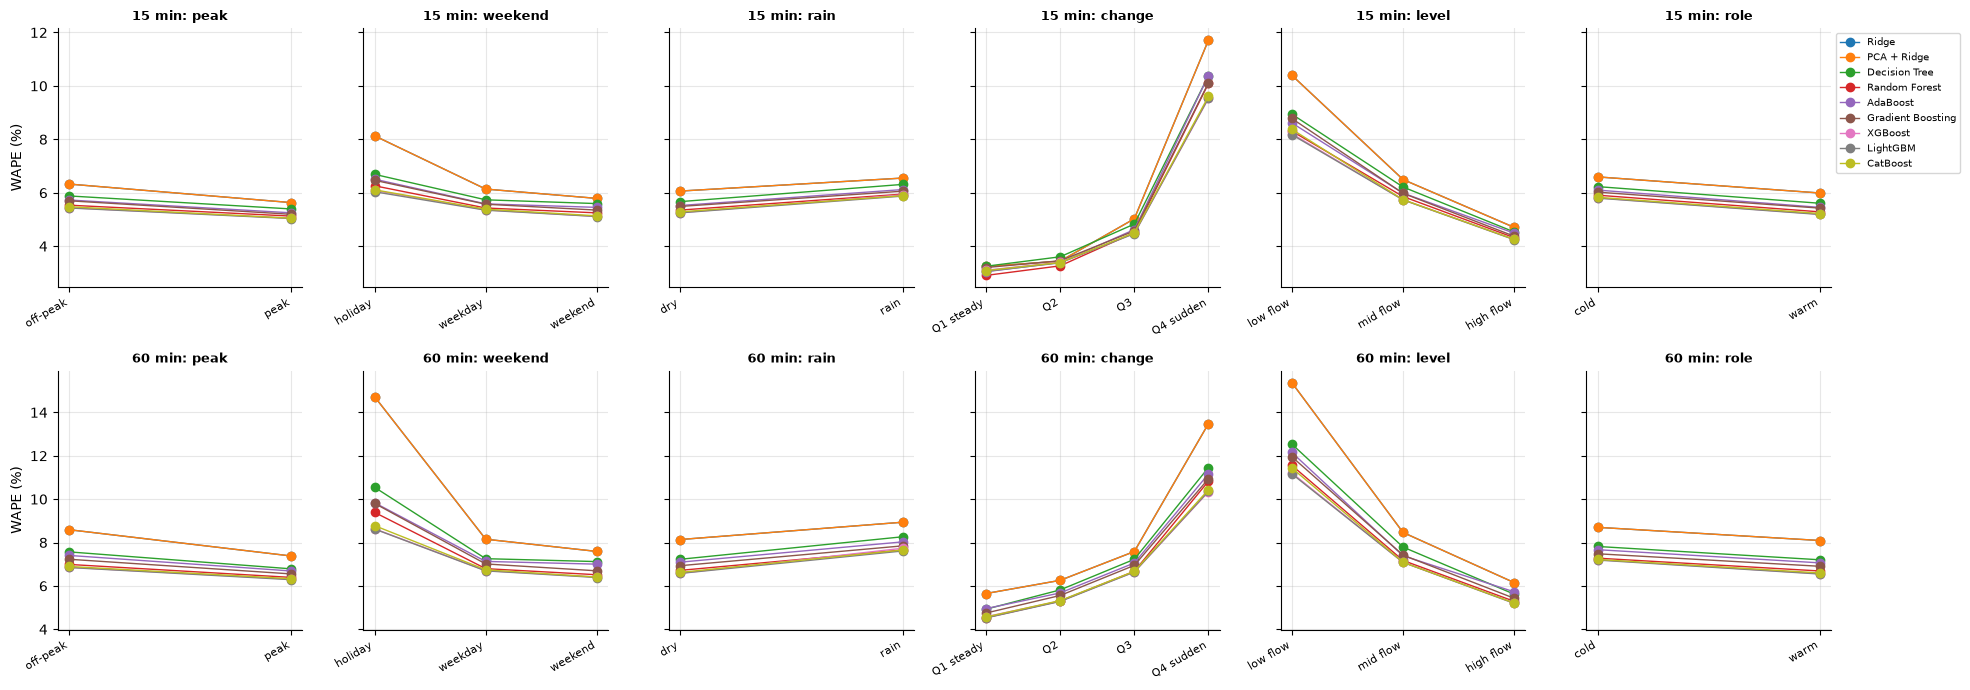

In [13]:
fig, axes = plt.subplots(2, len(SEGS), figsize=(3.3 * len(SEGS), 7), sharey="row")
for r, h in enumerate(ev.HORIZONS):
    for c, s in enumerate(SEGS):
        t = tables[(h, s)]
        for n in t.columns:
            axes[r, c].plot(range(len(t)), t[n], "o-", label=n, lw=1)
        axes[r, c].set_xticks(range(len(t))); axes[r, c].set_xticklabels([str(i) for i in t.index], rotation=30, ha="right", fontsize=8)
        axes[r, c].set_title(f"{h} min: {s}", fontsize=9)
axes[0, 0].set_ylabel("WAPE (%)"); axes[1, 0].set_ylabel("WAPE (%)")
axes[0, -1].legend(fontsize=7, ncol=1, loc="upper left", bbox_to_anchor=(1, 1))
savefig(fig, f"err_segments_{SPLIT}")

## 2. Error by hour of day, weekday vs weekend

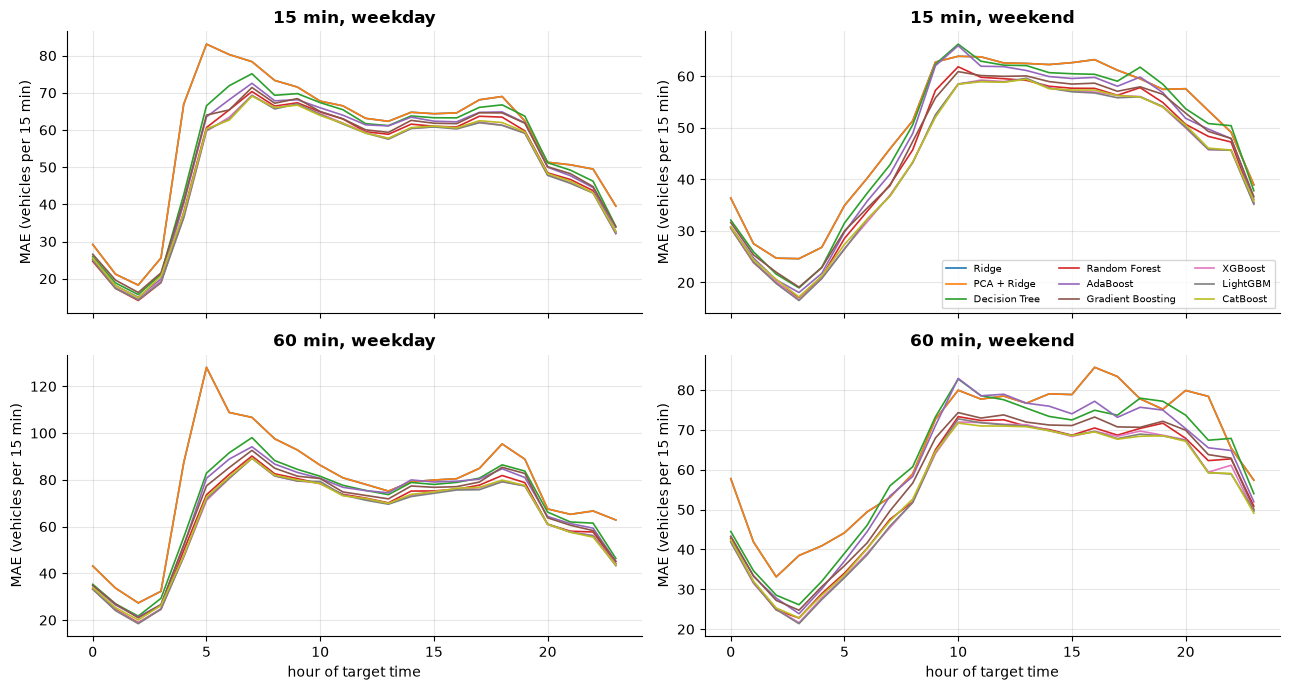

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for r, h in enumerate(ev.HORIZONS):
    for c, wk in enumerate(["weekday", "weekend"]):
        d = D[h][D[h]["weekend"] == wk]
        for n in MODELS:
            axes[r, c].plot(d.groupby("hour")[f"err_{n}"].apply(lambda e: e.abs().mean()), label=mo.LABEL[n], lw=1.2)
        axes[r, c].set_title(f"{h} min, {wk}"); axes[r, c].set_ylabel("MAE (vehicles per 15 min)")
axes[1, 0].set_xlabel("hour of target time"); axes[1, 1].set_xlabel("hour of target time")
axes[0, 1].legend(fontsize=7, ncol=3)
savefig(fig, f"err_by_hour_{SPLIT}")

## 3. Per sensor: is the average hiding a few bad sensors, and do models agree on which?

--- 15 min: ten worst sensors for LightGBM (WAPE %) ---
      Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost    corridor  role
ID2                                                                                                                               
2815   12.1         12.1           11.6           11.3      11.5               11.5     11.4      11.3      11.3   C3_I880-S  cold
2192   11.3         11.3           10.8           10.5      10.6               10.6     10.3      10.2      10.3   C1_I580-E  warm
2813   10.5         10.5           10.2            9.8      10.0               10.0      9.8       9.9       9.9   C3_I880-S  warm
2191   10.2         10.2           10.0            9.7       9.9                9.8      9.5       9.5       9.6   C1_I580-E  warm
2816   10.1         10.1            9.8            9.4       9.6                9.5      9.4       9.4       9.4   C3_I880-S  cold
2809    9.6          9.6   

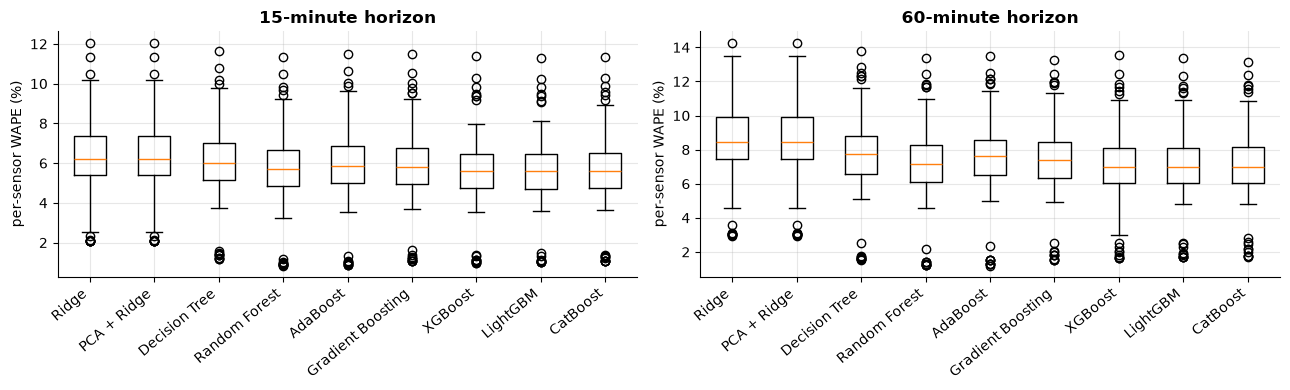

In [15]:
S = {}
for h in ev.HORIZONS:
    g = D[h].groupby("ID2")
    S[h] = pd.DataFrame({mo.LABEL[n]: g.apply(lambda x: M.wape(x["y_raw"], x[f"pred_{n}"]) * 100) for n in MODELS})
    S[h]["corridor"] = g["corridor"].first(); S[h]["role"] = g["role"].first()
    S[h].round(2).to_csv(ev.RESULTS / f"error_{SPLIT}_h{h}_per_sensor.csv")
    best = min(MODELS, key=lambda n: M.mae(D[h]["y_raw"], D[h][f"pred_{n}"]))
    print(f"--- {h} min: ten worst sensors for {mo.LABEL[best]} (WAPE %) ---")
    print(S[h].sort_values(mo.LABEL[best], ascending=False).head(10).round(1).to_string())
    print("rank correlation of per-sensor error between models (Spearman):")
    print(S[h][[mo.LABEL[n] for n in MODELS]].corr(method="spearman").round(2).to_string(), "\n")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h in zip(axes, ev.HORIZONS):
    ax.boxplot([S[h][mo.LABEL[n]].dropna() for n in MODELS], showfliers=True)
    ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels([mo.LABEL[n] for n in MODELS], rotation=40, ha="right")
    ax.set_ylabel("per-sensor WAPE (%)"); ax.set_title(f"{h}-minute horizon")
savefig(fig, f"err_per_sensor_{SPLIT}")

## 4. Do the models fail on the same observations?
Correlation of absolute errors between models, and the overlap of each model's worst 1 % of predictions.
High overlap means the hard cases are hard because of the data (incidents, faults), not because of one model's choices.

In [16]:
for h in ev.HORIZONS:
    A = pd.DataFrame({mo.LABEL[n]: D[h][f"err_{n}"].abs() for n in MODELS})
    print(f"--- {h} min: correlation of absolute errors ---")
    print(A.corr().round(2).to_string())
    top = {c: set(A[c].nlargest(int(len(A) * 0.01)).index) for c in A.columns}
    ref = mo.LABEL[min(MODELS, key=lambda n: M.mae(D[h]["y_raw"], D[h][f"pred_{n}"]))]
    print(f"share of {ref}'s worst 1% that is also in each model's worst 1%:")
    print({c: round(len(top[ref] & top[c]) / len(top[ref]), 2) for c in A.columns}, "\n")

--- 15 min: correlation of absolute errors ---
                   Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
Ridge               1.00         1.00           0.87           0.91      0.90               0.90     0.85      0.86      0.87
PCA + Ridge         1.00         1.00           0.87           0.91      0.90               0.90     0.85      0.86      0.87
Decision Tree       0.87         0.87           1.00           0.95      0.95               0.92     0.90      0.90      0.90
Random Forest       0.91         0.91           0.95           1.00      0.98               0.96     0.94      0.95      0.95
AdaBoost            0.90         0.90           0.95           0.98      1.00               0.95     0.92      0.93      0.93
Gradient Boosting   0.90         0.90           0.92           0.96      0.95               1.00     0.94      0.95      0.95
XGBoost             0.85         0.85           0.90           0.94    

## 5. The worst cases of the best model, and what they have in common

In [17]:
for h in ev.HORIZONS:
    d = D[h]; best = min(MODELS, key=lambda n: M.mae(d["y_raw"], d[f"pred_{n}"]))
    d = d.assign(abs_err=d[f"err_{best}"].abs(), pred=d[f"pred_{best}"], last_reading=d["flow_t"] * d["sc"])
    worst = d.nlargest(int(len(d) * 0.01), "abs_err")
    print(f"--- {h} min, {mo.LABEL[best]}: worst 1% = {len(worst):,} rows, they carry {worst['abs_err'].sum() / d['abs_err'].sum() * 100:.1f}% of all absolute error ---")
    cmp = pd.DataFrame({"share of worst 1% (%)": [worst[c].value_counts(normalize=True).get(v, 0) * 100 for c, v in
                        [("peak", "peak"), ("weekend", "weekend"), ("weekend", "holiday"), ("rain", "rain"), ("change", "Q4 sudden")]],
                        "share of all rows (%)": [d[c].value_counts(normalize=True).get(v, 0) * 100 for c, v in
                        [("peak", "peak"), ("weekend", "weekend"), ("weekend", "holiday"), ("rain", "rain"), ("change", "Q4 sudden")]]},
                       index=["peak hours", "weekends", "holidays", "rain", "sudden change (top quartile)"])
    print(cmp.round(1).to_string(), "\n")
    print(worst.sort_values("abs_err", ascending=False).head(15)[["target_time", "ID2", "corridor", "y_raw", "pred", "last_reading", "precip_mm", "weekend"]].round(0).to_string(), "\n")

--- 15 min, LightGBM: worst 1% = 8,681 rows, they carry 8.1% of all absolute error ---
                              share of worst 1% (%)  share of all rows (%)
peak hours                                     37.4                   22.7
weekends                                       19.9                   28.2
holidays                                        4.4                    3.6
rain                                           11.9                    9.8
sudden change (top quartile)                   95.1                   25.0 

                target_time   ID2    corridor   y_raw    pred  last_reading  precip_mm  weekend
69301   2019-03-04 00:30:00   719   C4_SR24-W  2079.0   -33.0         115.0        0.0  weekday
1091342 2019-09-20 12:00:00  1439  C2_US101-N     0.0  1754.0        1779.0        0.0  weekday
979605  2019-09-18 11:15:00  1432  C2_US101-N   151.0  1836.0        1802.0        0.0  weekday
1065021 2019-09-18 11:15:00  1436  C2_US101-N   156.0  1651.0        1666.0  

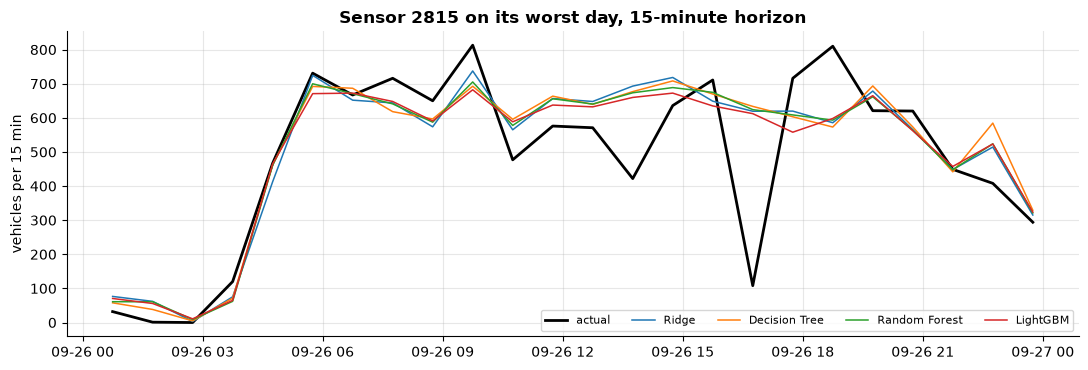

In [18]:
h = 15; d = D[h]; best = min(MODELS, key=lambda n: M.mae(d["y_raw"], d[f"pred_{n}"]))
worst_sensor = S[h][mo.LABEL[best]].idxmax()
day = d[(d["ID2"] == worst_sensor)]
day = day[day["target_time"].dt.normalize() == day.loc[day[f"err_{best}"].abs().idxmax(), "target_time"].normalize()].sort_values("target_time")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(day["target_time"], day["y_raw"], "k-", lw=2, label="actual")
for n in MODELS:
    if n in ("lgbm", "rf", "dt", "ridge"):
        ax.plot(day["target_time"], day[f"pred_{n}"], lw=1.1, label=mo.LABEL[n])
ax.set_title(f"Sensor {worst_sensor} on its worst day, 15-minute horizon"); ax.set_ylabel("vehicles per 15 min"); ax.legend(ncol=5, fontsize=8)
savefig(fig, f"err_worst_day_{SPLIT}")

## 6. Interpretation (2019 test split, LightGBM unless stated; WAPE in %, 15 min / 60 min)

1. **Peak, weekday/weekend, rain.** Segment differences are modest. Peak 5.04 / 6.29 against off-peak 5.43 / 6.85: peak is not harder, WAPE just divides by larger flows. Weekday 5.35 / 6.69, weekend 5.11 / 6.39, holiday 6.04 / 8.62, so holidays are the weakest calendar segment, and the gap grows with the horizon (+29% over weekdays at 60 min). Rain is harder than dry: 5.87 vs 5.25 at 15 min and 7.61 vs 6.58 at 60 min (+16%). Rainy and holiday rows are rare, so the models have little to learn from.
2. **Sudden changes are the main driver.** The steadiest quartile of rows (smallest move since the last reading) scores 3.06 / 4.52, the most sudden quartile 9.55 / 10.36, about 3.1 times worse at 15 min and 2.3 times at 60 min. Low-flow rows are about twice as hard as high-flow rows (8.18 vs 4.24 at 15 min, 11.17 vs 5.19 at 60 min) because a fixed error is a larger share of a small flow. Cold sensors (never seen in training) score 5.80 / 7.19 against 5.19 / 6.55 for warm sensors, a cost of about 12% at 15 min and 10% at 60 min.
3. **Sensors.** The typical sensor has a WAPE of 5.58 (15 min) and 6.96 (60 min). The hardest at 15 min are 2815 (11.27), 2192 (10.25) and 2813 (9.85); at 60 min 722 (13.39) and 2815 (12.35). Eight sensors (2185 to 2190, 2806, 2814) score about 1.0 to 1.1 at 15 min and 1.7 to 2.5 at 60 min. These are the template sensors found in the data audit: about 96% of their readings repeat the reading from a week earlier, so they are almost free to predict and pull the all-rows average down. Without them the other 92 sensors score 5.69 / 7.11. The per-sensor ranking is nearly the same for every model (Spearman 0.97 to 1.00), so hard sensors are hard for the data, not for one model.
4. **Model differences.** The boosted models make the same mistakes: the correlation of their absolute errors is 0.96 to 0.98, and the worst 1% of rows carries 8.1% (15 min) and 8.3% (60 min) of all absolute error, 95% and 82% of it in the most sudden quartile. The error comes from the rows, not from the choice of model, which is why the top three models are within about 0.3 MAE of each other.
5. **Limitations.** The remaining error cannot be explained from the features. The worst rows are feed outages: on 2019-09-20 12:00, 18 of 100 sensors read exactly 0 and 29 were below 20% of their usual flow; on 2019-09-18 11:15, 23 sensors were below 20%; on 2019-04-05 09:45, 29 were below 50%. Four separate freeways cannot collapse in the same 15 minutes, so these are sensor-feed dropouts. Sensor 719 (C4_SR24-W) has isolated night spikes (2.5% of its night bins above 1,000 vehicles per 15 min, up to 2,181 in 2019) that the cleaning rule does not flag. Incidents and roadworks are not in the inputs at all. No model was changed because of this analysis; the test split was read once and described.
